# Requirements

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, accuracy_score, confusion_matrix, brier_score_loss,
                             recall_score, precision_score, roc_curve)

# Data

In [3]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


 ## Origional Markov Chain 

 The code has been adjusted to fit the format of the data in this project but is the same otherwise.

In [8]:
import numpy as np
import pandas as pd

state_names = ["current", "1_month_late", "2_months_late", "3plus_months_late"]
K_ow = 4

def to_state_ow(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p <= 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s

# chronological order: PAY_6 (oldest) ... PAY_1 (most recent)
pay_chrono = sorted(pay_cols, key=lambda c: -int(c.split("_")[1]))

S_tr = to_state_ow(train[pay_chrono].values)
S_va = to_state_ow(validation[pay_chrono].values)
S_te = to_state_ow(test[pay_chrono].values)

y_tr_a, y_va_a, y_te_a = (np.asarray(v).astype(int) for v in (y_tr, y_va, y_te))

# 1) transition matrix (TRAIN only, Laplace smoothing)
counts = np.ones((K_ow, K_ow))
for a, b in zip(S_tr[:, :-1].ravel(), S_tr[:, 1:].ravel()):
    counts[a, b] += 1
P_ow = counts / counts.sum(axis=1, keepdims=True)

# 2) default rate by latest state, shrunk toward the global rate (TRAIN only)
latest_tr = S_tr[:, -1]
global_rate = y_tr_a.mean()
shrink = 20
risk_by_state = np.array([
    (y_tr_a[latest_tr == k].sum() + shrink * global_rate) / ((latest_tr == k).sum() + shrink)
    for k in range(K_ow)
])

# 3) one-step Markov projection: P(default) = sum_j P[latest, j] * risk[j]
def predict_onestep(S):
    return P_ow[S[:, -1]] @ risk_by_state

p_mk_onestep_va = predict_onestep(S_va)
p_mk_onestep_te = predict_onestep(S_te)

# inspect
print(pd.DataFrame(P_ow, index=state_names, columns=state_names).round(3))
print(pd.Series(risk_by_state, index=state_names).round(3))

from sklearn.metrics import roc_auc_score, log_loss
print("val AUC", roc_auc_score(y_va_a, p_mk_onestep_va),
      "test AUC", roc_auc_score(y_te_a, p_mk_onestep_te),
      "test logloss", log_loss(y_te_a, p_mk_onestep_te))


                   current  1_month_late  2_months_late  3plus_months_late
current              0.939         0.014          0.047              0.000
1_month_late         0.042         0.875          0.042              0.042
2_months_late        0.255         0.102          0.578              0.065
3plus_months_late    0.104         0.085          0.281              0.531
current              0.142
1_month_late         0.322
2_months_late        0.686
3plus_months_late    0.676
dtype: float64
val AUC 0.7098305994570099 test AUC 0.7088284613042087 test logloss 0.46078179195670793


This has a few problems which can be identified. Since each state only cares about the state it is in, there is no distinction between being a month late for a single month and having been a month late for 6 months for example. Being able to distinguish between these could help the model be a stronger predictor. Also since the transition matrix is pooled over defaulters and non-defaulters 

# Markov Chain 
To build on work from the previous sprint the new model uses a two class markov chain classifier. The train data is seperated into defaulter and non defaulter and the model learns how each class moves between payment status states. The train data is scored based on how much more likely their sequence is from the default chain as opposed to the non default chain. This allows the model to consider history as opposed to the pooled data only considering the most recent state. It is likely the dynamics among these two classes are different so when combining them it compresses to the mean of both. The average of groups is less significant in this instance as what is most important is the behavour of the defaulters. A drawback of this is that since defaulters only make up about 22% of the dataset the default chain is sparse in data. The model is also more likely to overfit so it is important to compare performance of train data with test. This does not adress the time homogeniousity or first order dependence of the matrices constructed.

For the new two class model, we will fit it with different states which we can then compare and see how it affects the results. I have chosen three data splits:
- each type of on time payment seperate, 
- combine no bill and fully paid,
- combine all on time payments.

For the final one the chain only has four states as separating higher than 3 months late leads to very limited data in late columns.

- experiment with states and what other data can be added 
- cross validation

In [18]:
#function for each split of the Markov model
#original 5 states
def to_state_5full(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s
#merges -2 and -1 into one state ()
def to_state_5negmerge(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 1; s[p == 1] = 2; s[p == 2] = 3; s[p >= 3] = 4
    return s
#merges -2, -1 and 0 into one state (not late)
def to_state_4nolate(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s

# ---- state mappings ----
def make_to_state(mapping, top):
    # mapping: dict raw value -> state; any raw value >= top maps to the last state
    def f(p):
        p = np.asarray(p); s = np.empty(p.shape, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        s[p >= top] = max(mapping.values()) + 1 if top > max(mapping) else mapping[top]
        return s
    return f

explain the model include some maths 

In [19]:



# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m

# ---- build all three ----
markov_models = {
    "mk5_full":     build_markov("mk5_full",     to_state_5full,     5),
    "mk5_negmerge": build_markov("mk5_negmerge", to_state_5negmerge, 5),
    "mk4_nolate":   build_markov("mk4_nolate",   to_state_4nolate,   4),
}

# named probability vectors, matching your existing p_mk_va / p_mk_te style
p_mk5_full_va,     p_mk5_full_te     = markov_models["mk5_full"]["p_va"],     markov_models["mk5_full"]["p_te"]
p_mk5_negmerge_va, p_mk5_negmerge_te = markov_models["mk5_negmerge"]["p_va"], markov_models["mk5_negmerge"]["p_te"]
p_mk4_nolate_va,   p_mk4_nolate_te   = markov_models["mk4_nolate"]["p_va"],   markov_models["mk4_nolate"]["p_te"]

## Matrix Heatmaps

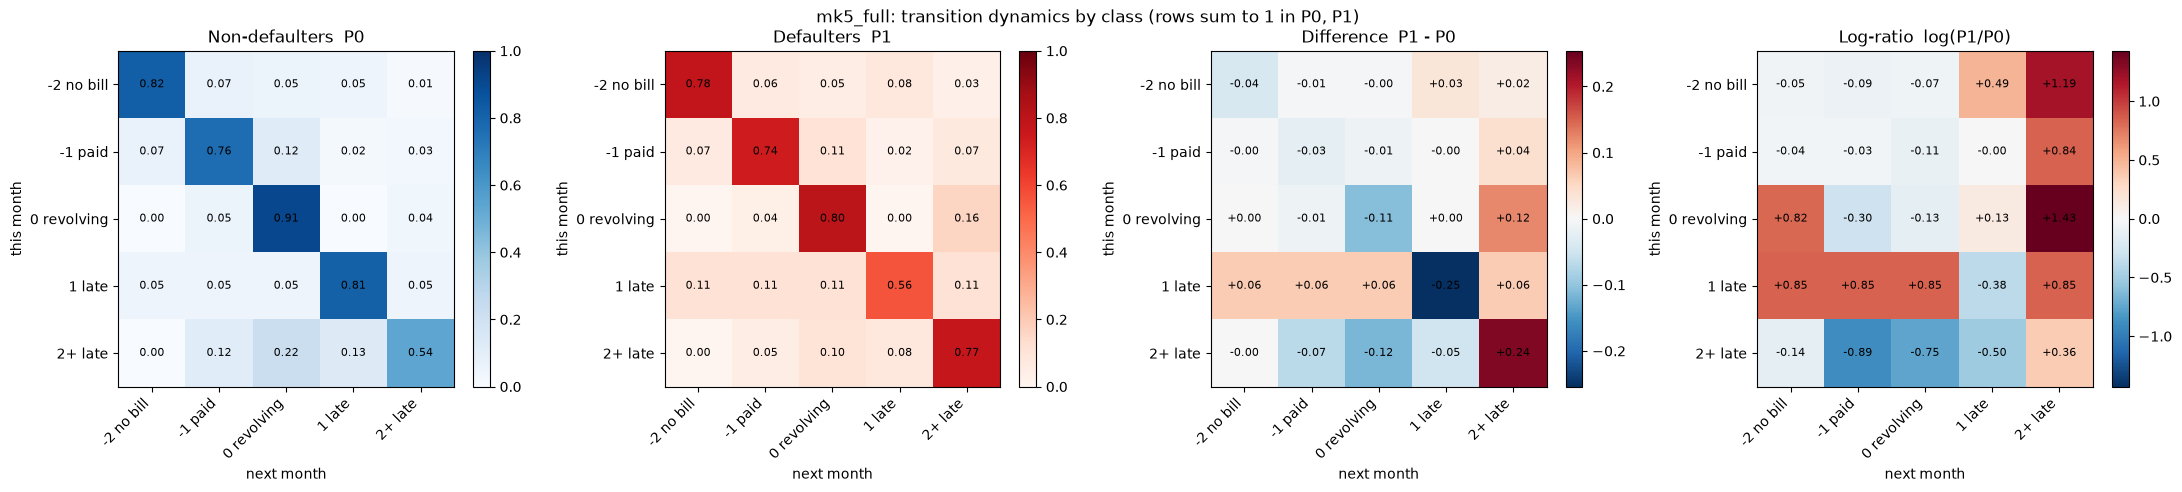

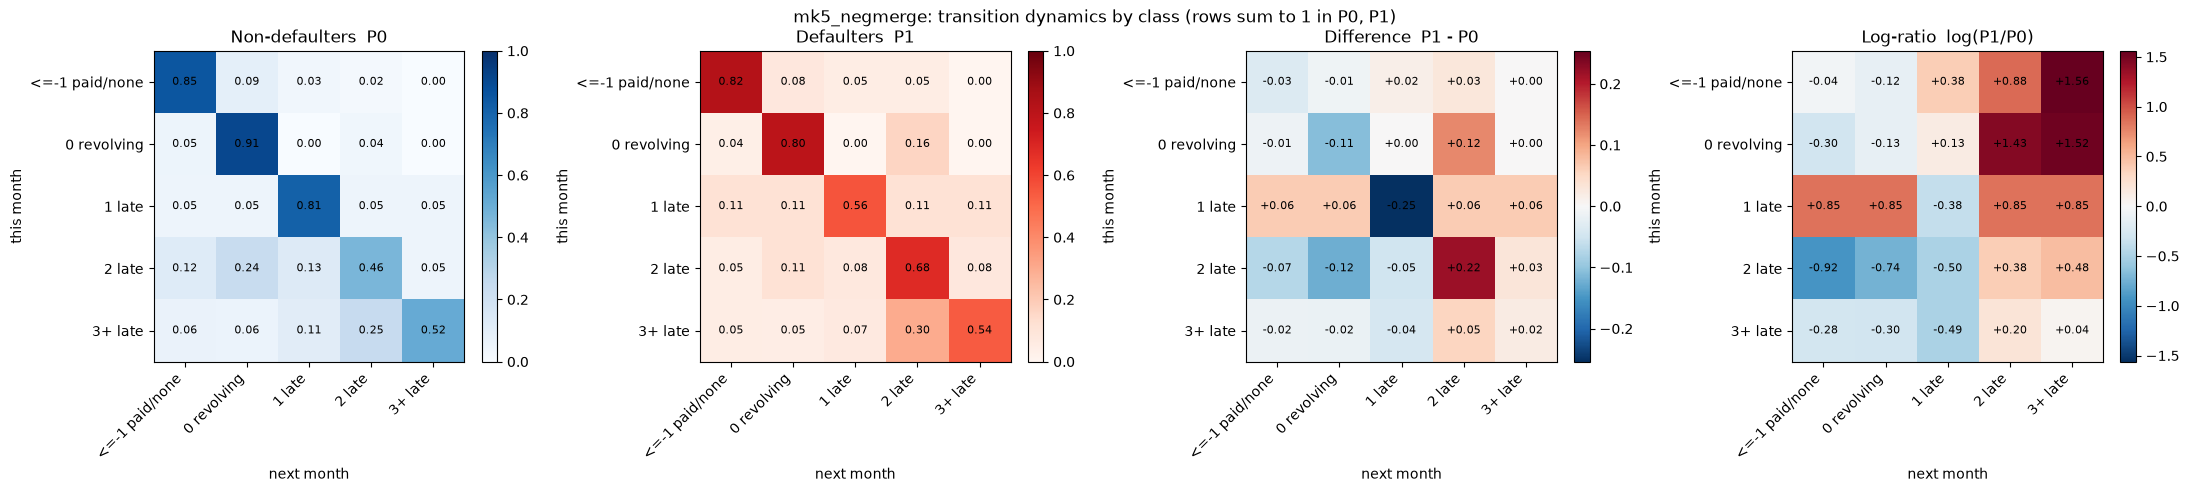

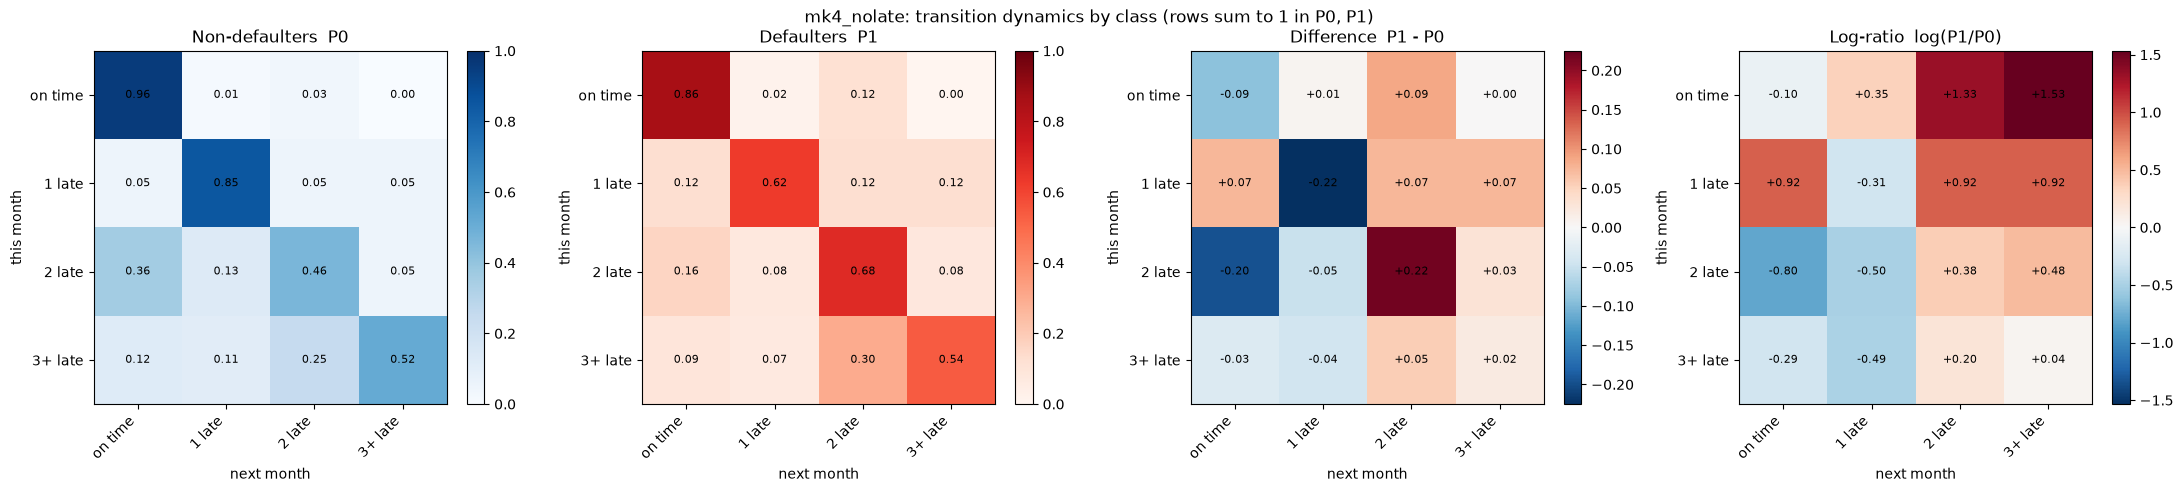

In [29]:
import numpy as np, matplotlib.pyplot as plt

labels = {
    "mk5_full":     ["-2 no bill", "-1 paid", "0 revolving", "1 late", "2+ late"],
    "mk5_negmerge": ["<=-1 paid/none", "0 revolving", "1 late", "2 late", "3+ late"],
    "mk4_nolate":   ["on time", "1 late", "2 late", "3+ late"],
}

def annotate(ax, M, fmt, color_thresh=None):
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=8)

def plot_class_heatmaps(key):
    m = markov_models[key]; P0, P1, lab = m["P0"], m["P1"], labels[key]
    diff = P1 - P0
    logr = np.log(P1) - np.log(P0)
    fig, axs = plt.subplots(1, 4, figsize=(22, 4.8))
    panels = [
        (P0,   "Non-defaulters  P0",        "Blues", (0, 1), ".2f"),
        (P1,   "Defaulters  P1",            "Reds",  (0, 1), ".2f"),
        (diff, "Difference  P1 - P0",       "RdBu_r", (-np.abs(diff).max(), np.abs(diff).max()), "+.2f"),
        (logr, "Log-ratio  log(P1/P0)",     "RdBu_r", (-np.abs(logr).max(), np.abs(logr).max()), "+.2f"),
    ]
    for ax, (M, title, cmap, (lo, hi), fmt) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi)
        ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=45, ha="right")
        ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab)
        ax.set_xlabel("next month"); ax.set_ylabel("this month"); ax.set_title(title)
        annotate(ax, M, fmt); plt.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{key}: transition dynamics by class (rows sum to 1 in P0, P1)")
    plt.tight_layout(); plt.show()

for k in markov_models:
    plot_class_heatmaps(k)

### Interpretation of Heatmaps

#### mk5 Full

The P0 and P1 matrices both have strong diagonal enteries. Defaulters are less stable in the not late states which matches general intuition which is a good sign. The weakest P0 diagonal being the 2+ late with a value of only 0.54 Here there is a 34% chance of returning to an on time payment. This behavour is not seen in P1 which has a much stronger 0.77 diagonal entry and only a 15% chance of returning to a non late status. What is less expected is the non defaulters are more likely to remain 1 month over than defaulters. This result is likely an artifact of smoothing due to the limited data size

## Count Heatmaps

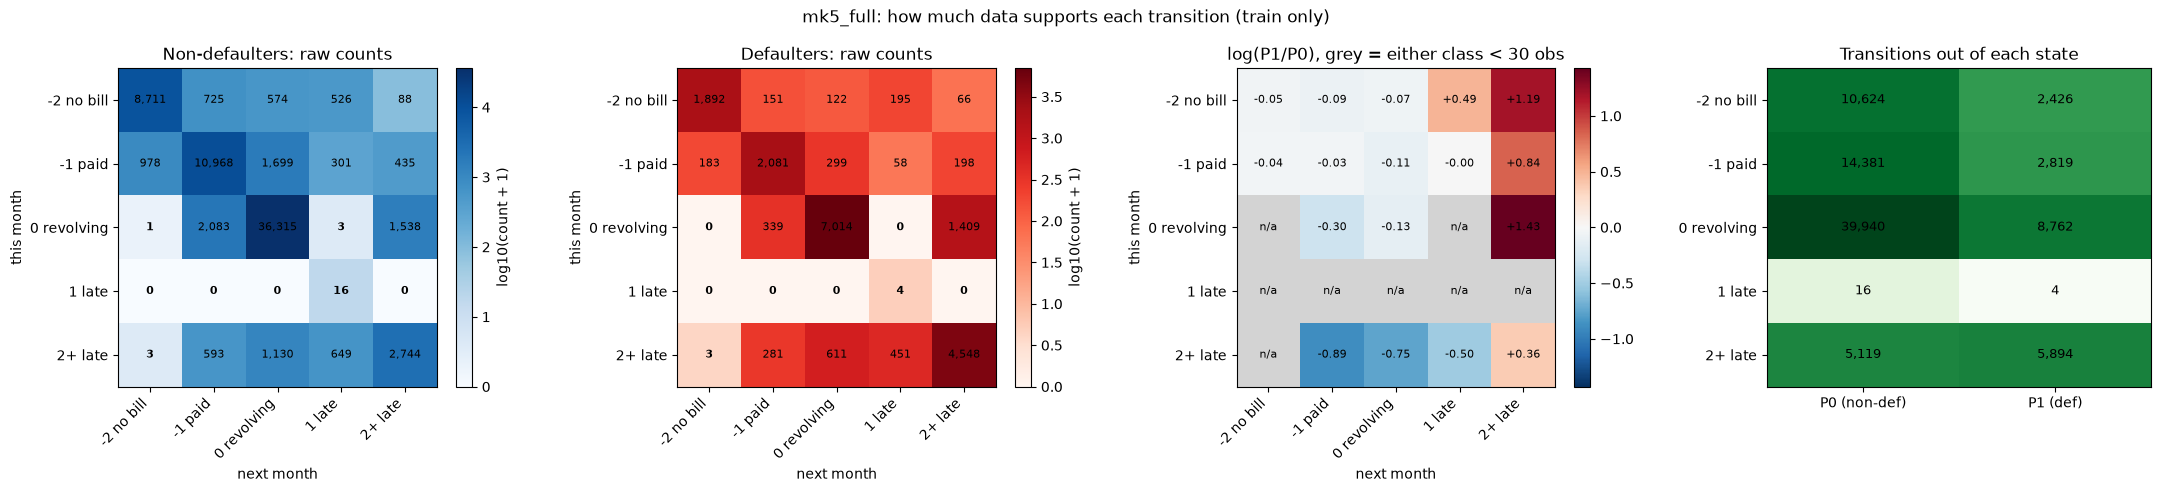

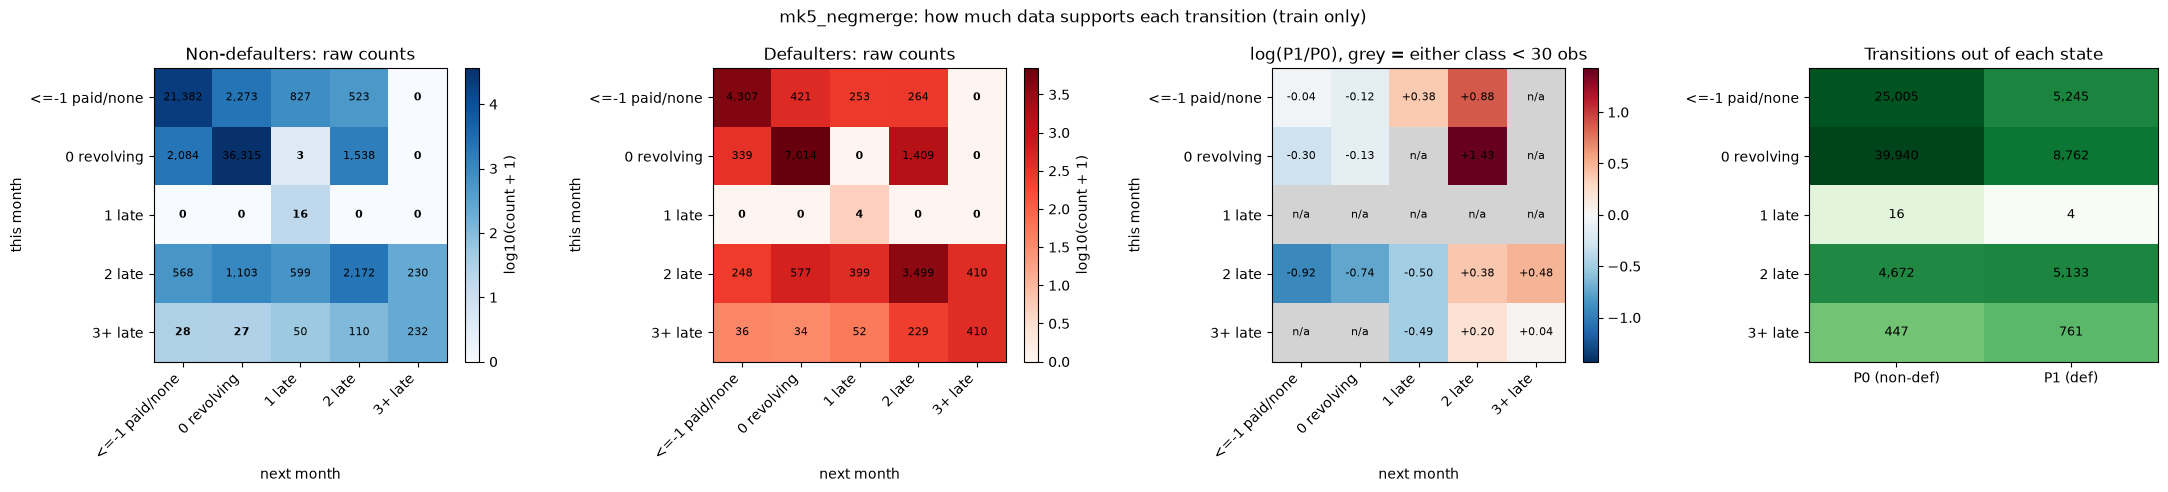

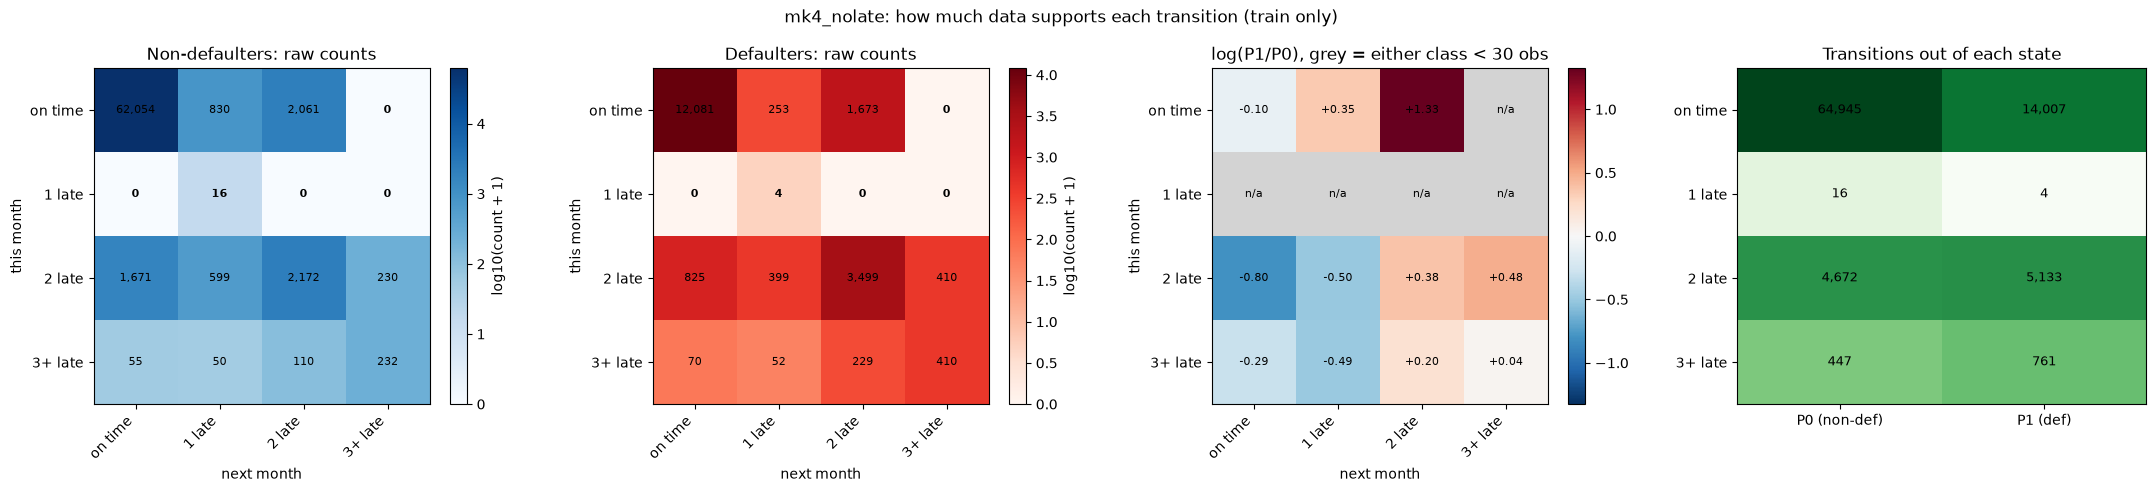

In [34]:
import numpy as np, matplotlib.pyplot as plt

MIN_N = 30  # cells with fewer raw transitions than this are flagged as unreliable

def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def plot_count_heatmaps(key, min_n=MIN_N):
    m = markov_models[key]; K = m["K"]; lab = labels[key]
    S = m["to_state"](train[pay_cols].values)
    C0 = raw_counts(S[y_tr == 0], K)
    C1 = raw_counts(S[y_tr == 1], K)

    fig, axs = plt.subplots(1, 4, figsize=(22, 4.8))

    for ax, C, title, cmap in [(axs[0], C0, "Non-defaulters: raw counts", "Blues"),
                               (axs[1], C1, "Defaulters: raw counts", "Reds")]:
        im = ax.imshow(np.log10(C + 1), cmap=cmap)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{C[i, j]:,}", ha="center", va="center", fontsize=8,
                        fontweight="bold" if C[i, j] < min_n else "normal",
                        color="black")
        cb = plt.colorbar(im, ax=ax, fraction=0.046); cb.set_label("log10(count + 1)")
        ax.set_title(title)

    low = np.minimum(C0, C1) < min_n
    P0, P1 = m["P0"], m["P1"]
    logr = np.log(P1) - np.log(P0)
    masked = np.ma.array(logr, mask=low)
    lim = np.abs(masked).max()
    cmap = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("lightgrey")
    im = axs[2].imshow(masked, cmap=cmap, vmin=-lim, vmax=lim)
    for i in range(K):
        for j in range(K):
            axs[2].text(j, i, "n/a" if low[i, j] else f"{logr[i, j]:+.2f}",
                        ha="center", va="center", fontsize=8)
    plt.colorbar(im, ax=axs[2], fraction=0.046)
    axs[2].set_title(f"log(P1/P0), grey = either class < {min_n} obs")

    row_n = np.vstack([C0.sum(1), C1.sum(1)]).T
    axs[3].imshow(np.log10(row_n + 1), cmap="Greens", aspect="auto")
    for i in range(K):
        for c in range(2):
            axs[3].text(c, i, f"{row_n[i, c]:,}", ha="center", va="center", fontsize=9)
    axs[3].set_xticks([0, 1]); axs[3].set_xticklabels(["P0 (non-def)", "P1 (def)"])
    axs[3].set_title("Transitions out of each state")

    for ax in axs[:3]:
        ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
        ax.set_yticks(range(K)); ax.set_yticklabels(lab)
        ax.set_xlabel("next month"); ax.set_ylabel("this month")
    axs[3].set_yticks(range(K)); axs[3].set_yticklabels(lab)

    fig.suptitle(f"{key}: how much data supports each transition (train only)")
    plt.tight_layout(); plt.show()

    return C0, C1

counts_out = {k: plot_count_heatmaps(k) for k in markov_models}

This count cell clearly displays the data issue. could either merge 1 into 2+ or make a 1-2 and a 3+ state, would merging 1 and 0 be unwise?
 redo splits and see new heat maps more to compare later.

In [ ]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m

# ---- build all three ----
markov_models = {
    "mk5_full":     build_markov("mk5_full",     to_state_5full,     5),
    "mk5_negmerge": build_markov("mk5_negmerge", to_state_5negmerge, 5),
    "mk4_nolate":   build_markov("mk4_nolate",   to_state_4nolate,   4),
}

# named probability vectors, matching your existing p_mk_va / p_mk_te style
p_mk5_full_va,     p_mk5_full_te     = markov_models["mk5_full"]["p_va"],     markov_models["mk5_full"]["p_te"]
p_mk5_negmerge_va, p_mk5_negmerge_te = markov_models["mk5_negmerge"]["p_va"], markov_models["mk5_negmerge"]["p_te"]
p_mk4_nolate_va,   p_mk4_nolate_te   = markov_models["mk4_nolate"]["p_va"],   markov_models["mk4_nolate"]["p_te"]

In [35]:
# =========================================================
# 1. Markov chain model
# =========================================================
K = 5
def to_state(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s

S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))

def fit_chain(S, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

init0, P0 = fit_chain(S_tr[y_tr == 0])                     # fitted on TRAIN only
init1, P1 = fit_chain(S_tr[y_tr == 1])
log_prior = np.log(y_tr.mean() / (1 - y_tr.mean()))

def llr(S):
    sc = np.log(init1[S[:, 0]]) - np.log(init0[S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(P1[S[:, t], S[:, t+1]]) - np.log(P0[S[:, t], S[:, t+1]])
    return sc + log_prior

sc_tr, sc_va, sc_te = llr(S_tr), llr(S_va), llr(S_te)

# Platt calibration fitted on VALIDATION scores
platt = LogisticRegression(C=1e6).fit(sc_va.reshape(-1, 1), y_va)
p_mk_va = platt.predict_proba(sc_va.reshape(-1, 1))[:, 1]
p_mk_te = platt.predict_proba(sc_te.reshape(-1, 1))[:, 1]


In [36]:
# =========================================================
# 1. Markov chain model (Combine -2 and -1 into one state)
# =========================================================
K = 5
def to_state(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 1; s[p == 1] = 2; s[p == 2] = 3; s[p >= 3] = 4
    return s


In [37]:
# =========================================================
# 1. Markov chain model (Combine -2, -1 and 0 into one state)
# =========================================================
K = 4
def to_state(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s


Analysis of model, cross validation, AUC

# Random Forest

In [38]:
# =========================================================
# 2. Random forest (+ optional gradient boosting)
# =========================================================
def make_features(d):
    X = d.drop(columns=TARGET).copy(); L = X["LIMIT_BAL"]
    B, A = X[bill_cols].values, X[amt_cols].values
    X["n_late"]      = (X[pay_cols] > 0).sum(axis=1)
    X["max_delay"]   = X[pay_cols].max(axis=1)
    X["mean_pay"]    = X[pay_cols].mean(axis=1)
    X["recent_late"] = (X[["PAY_1", "PAY_2"]] > 0).sum(axis=1)
    X["n_revolve"]   = (X[pay_cols] == 0).sum(axis=1)
    X["pay_slope"]   = X["PAY_1"] - X["PAY_6"]
    X["util_1"]      = B[:, -1] / L
    X["util_mean"]   = B.mean(axis=1) / L
    X["util_max"]    = B.max(axis=1) / L
    X["bill_trend"]  = (B[:, -1] - B[:, 0]) / L
    X["repay_ratio"] = A.sum(axis=1) / (np.clip(B, 0, None).sum(axis=1) + 1)
    X["zero_pay_n"]  = (A == 0).sum(axis=1)
    X["bill_vol"]    = B.std(axis=1) / (np.abs(B).mean(axis=1) + 1)
    return X

X_tr, X_va, X_te = make_features(train), make_features(validation), make_features(test)

models = {
    "RF": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "HGB": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=200,
                                          l2_regularization=1, random_state=42),
}
for m in models.values(): m.fit(X_tr, y_tr)